<a href="https://colab.research.google.com/github/reitezuz/18NES2-2026/blob/main/week08/variational_autoencoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Variational autoencoder – generating handwritten digits with MNIST

Based on:
- [Deep Learning with Python – Chapter 17: Image generation](https://github.com/fchollet/deep-learning-with-python-notebooks/blob/master/chapter17_image-generation.ipynb)
- [Keras example: Variational AutoEncoder](https://keras.io/examples/generative/vae/)

In this notebook, we will build a convolutional variational autoencoder (VAE) to learn a low-dimensional latent representation of handwritten digits and generate new images by sampling from the latent space.

We will use the familiar MNIST dataset of 28 × 28 grayscale digit images, available through `keras.datasets.mnist.load_data()`. The model will learn from the images without using their digit labels.

In [ ]:
# !pip install keras keras-hub --upgrade -q

In [ ]:
import os
os.environ["KERAS_BACKEND"] = "jax"

In [ ]:
# @title
import os
from IPython.core.magic import register_cell_magic

@register_cell_magic
def backend(line, cell):
    current, required = os.environ.get("KERAS_BACKEND", ""), line.split()[-1]
    if current == required:
        get_ipython().run_cell(cell)
    else:
        print(f"This cell requires the {required} backend. To run it, change KERAS_BACKEND to \"{required}\" at the top of the notebook, restart the runtime, and rerun the notebook.")

## Implement a VAE

### Build the encoder
The encoder predicts the parameters of a diagonal Gaussian distribution for each input image:

- `z_mean`: the mean vector $\mu$.
- `z_log_var`: the logarithm of the variance, $\log \sigma^2$, for each latent dimension.

In [ ]:
import keras
from keras import layers


def get_encoder(latent_dim=2):
    """Build the encoder predicting the latent mean and log variance."""
    image_inputs = keras.Input(shape=(28, 28, 1))

    # Extract features and downsample the image
    x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(image_inputs)
    x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)

    # Convert feature maps into a feature vector
    x = layers.Flatten()(x)
    x = layers.Dense(16, activation="tanh")(x)

    # Predict the parameters of the latent distribution
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

    return keras.Model(image_inputs, [z_mean, z_log_var], name="encoder")

encoder = get_encoder(latent_dim=2)

### Sampling and the reparameterization trick

The `Sampler` layer transforms samples from a standard normal distribution into samples from a normal distribution with the mean and variance predicted by the encoder.

- It uses the **reparameterization trick**:
$$
\epsilon \sim \mathcal{N}(0, I),
\qquad
z = \mu + \sigma \odot \epsilon.
$$
Here, $\odot$ denotes element-wise multiplication. Since the encoder outputs the log variance, the standard deviation is computed as:

$$
\sigma = \exp\left(\frac{1}{2}\log \sigma^2\right).
$$

- Instead of sampling directly from a distribution whose parameters depend on the encoder, we sample independent standard normal noise and transform it using the predicted parameters. This allows gradients to flow through $\mu$ and $\sigma$ during backpropagation, so the encoder can be trained.

The layer samples one latent vector per image, producing an output of shape `(batch_size, latent_dim)`. The `SeedGenerator` maintains a random state so that successive calls produce fresh noise.

In [ ]:
from keras import ops


class Sampler(keras.Layer):
    """Sample a latent vector using the reparameterization trick."""

    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator()
        self.built = True

    def call(self, z_mean, z_log_var):
        # Get the batch size and latent dimensionality
        batch_size = ops.shape(z_mean)[0]
        z_size = ops.shape(z_mean)[1]

        # Sample standard normal noise
        epsilon = keras.random.normal(
            (batch_size, z_size), seed=self.seed_generator
        )

        # Transform the noise using the predicted mean and standard deviation
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon

### Build the decoder

The decoder maps a latent vector to a 28 × 28 grayscale image. Transposed convolutions gradually increase the spatial resolution, and the final sigmoid activation produces pixel values between 0 and 1.

In [ ]:
def get_decoder(latent_dim=2):
    """Build the decoder mapping latent vectors to images."""
    latent_inputs = keras.Input(shape=(latent_dim,))

    # Project the latent vector into 7 × 7 feature maps
    x = layers.Dense(7 * 7 * 64, activation="relu")(latent_inputs)
    x = layers.Reshape((7, 7, 64))(x)

    # Upsample from 7 × 7 to 14 × 14, then to 28 × 28
    x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
    x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)

    # Produce a single-channel image with pixel values in [0, 1]
    decoder_outputs = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)

    return keras.Model(latent_inputs, decoder_outputs, name="decoder")


decoder = get_decoder(latent_dim=2)
decoder.summary(line_length=80)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)        │ (None, 2)                │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_1 (Dense)                   │ (None, 3136)             │         9,408 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ reshape (Reshape)                 │ (None, 7, 7, 64)         │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_transpose                  │ (None, 14, 14, 64)       │        36,928 │
│ (Conv2DTranspose)                 │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_transpose_1                │ (None, 28, 28, 32)       │        18,464 │
│ (Conv2DTranspose)                 │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)                 │ (None, 28, 28, 1)        │           289 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 65,089 (254.25 KB)

 Trainable params: 65,089 (254.25 KB)

 Non-trainable params: 0 (0.00 B)

### Build the variational autoencoder

The `VAE` class combines the encoder, sampler, and decoder into a model with a custom loss. It inherits from `keras.Model`, allowing us to train it using `compile()` and `fit()`.

#### Forward pass and reconstruction

In this implementation, `call()` returns the encoder outputs: `z_mean` and `z_log_var`. Sampling and decoding take place inside `compute_loss()`:

1. The encoder predicts a latent distribution for each input image.
2. The sampler draws a latent vector from that distribution.
3. The decoder maps this vector back to an image.

The input image itself serves as the reconstruction target, so the labels `y` are not used.

#### Reconstruction loss

- The reconstruction loss measures how well the decoded image matches the input. We use binary cross-entropy with pixel values normalized to the range [0, 1].
- For these single-channel images, `binary_crossentropy()` reduces the channel axis and returns a tensor of shape `(batch_size, 28, 28)`. We sum over the two spatial dimensions to obtain one loss per image, then average over the batch.
- This term encourages the encoder and decoder to preserve the information needed to reconstruct the input.


#### KL divergence

- The KL divergence measures how much the encoder's predicted latent distribution differs from the standard normal prior:
$$
q(z \mid x) = \mathcal{N}\left(\mu, \operatorname{diag}(\sigma^2)\right),
\qquad
p(z) = \mathcal{N}(0, I).
$$
- For each image, it is computed as:
$$
D_{\mathrm{KL}}\bigl(q(z \mid x) \,\|\, p(z)\bigr)
=
\frac{1}{2}\sum_{j=1}^{d}
\left(
\mu_j^2 + \sigma_j^2 - 1 - \log \sigma_j^2
\right),
$$
where $d$ is the latent dimensionality. In the code, we sum over latent dimensions and then average over the batch.
- This term encourages the predicted distributions to stay close to the standard normal prior, regularizing the latent space so that we can generate images by sampling latent vectors from that prior.

#### Total loss and tracking

- The total loss combines reconstruction quality with latent-space regularization:
$$
\mathcal{L}
=
\mathcal{L}_{\text{reconstruction}}
+
\mathcal{L}_{\text{KL}}.
$$
- Both components are summed over their respective dimensions (pixels or latent coordinates) and averaged over the batch.

The two `Mean` trackers record the reconstruction and KL losses separately during training.

In [ ]:
class VAE(keras.Model):
    """Combine the encoder, sampler, and decoder with a custom VAE loss."""

    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.sampler = Sampler()

        # Track the two components of the loss
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    def call(self, inputs):
        # Predict the parameters of the latent distribution
        return self.encoder(inputs)

    def compute_loss(self, x, y, y_pred, sample_weight=None, training=True):
        # Sample a latent vector and reconstruct the input image
        z_mean, z_log_var = y_pred
        z = self.sampler(z_mean, z_log_var)
        reconstruction = self.decoder(z)

        # Sum reconstruction errors over pixels, then average over the batch
        reconstruction_loss = ops.mean(ops.sum(keras.losses.binary_crossentropy(x, reconstruction), axis=(1, 2),))

        # Compute the KL divergence contribution for each latent dimension
        kl_loss = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))

        # Sum KL contributions over latent dimensions, then average over the batch
        kl_loss = ops.mean(ops.sum(kl_loss, axis=1))

        # Combine the two loss components
        total_loss = reconstruction_loss + kl_loss

        # Update the loss trackers
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return total_loss

## Train the VAE on MNIST

We combine the MNIST training and test images for this generative demonstration, add a channel dimension, and normalize pixel values to [0, 1]. The VAE is trained to reconstruct the images without using digit labels.

In [ ]:
import numpy as np

# Load the images without labels and combine both subsets
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()
mnist_digits = np.concatenate([x_train, x_test], axis=0)

# Add the channel dimension and normalize pixel values to [0, 1]
mnist_digits = np.expand_dims(mnist_digits, -1).astype("float32") / 255

# Create and compile the VAE
vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam())

# Train using the input images as reconstruction targets
history = vae.fit(mnist_digits, epochs=30, batch_size=128)

Epoch 1/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - kl_loss: 3.3625 - loss: 197.6117 - reconstruction_loss: 194.2440
Epoch 2/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - kl_loss: 4.6362 - loss: 163.2485 - reconstruction_loss: 158.6107
Epoch 3/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - kl_loss: 5.4156 - loss: 156.5388 - reconstruction_loss: 151.1226
Epoch 4/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - kl_loss: 5.7750 - loss: 153.2711 - reconstruction_loss: 147.4942
Epoch 5/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - kl_loss: 5.9713 - loss: 151.2686 - reconstruction_loss: 145.2968
Epoch 6/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - kl_loss: 6.0734 - loss: 150.0286 - reconstruction_loss: 143.9549
Epoch 7/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - kl_loss: 6.1455 - loss: 149.0376 - reconstruction_loss: 142.8916
Epoch 8/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - kl_loss: 6.2115 - loss: 148.1288 - reconstruction_loss: 141.9170
Epoch 9/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/s

### Training loss curves

The two plots show the reconstruction loss and KL divergence on the training data.

- **Reconstruction loss typically decreases:** the model learns to reconstruct the input images more accurately.
- **KL divergence may increase:** the encoder learns image-dependent latent distributions that carry useful information for reconstruction, moving away from the standard normal prior.

This is a common pattern, but neither curve has to change monotonically. The model balances reconstruction quality against latent-space regularization, so the KL divergence may also decrease, fluctuate, or stabilize.

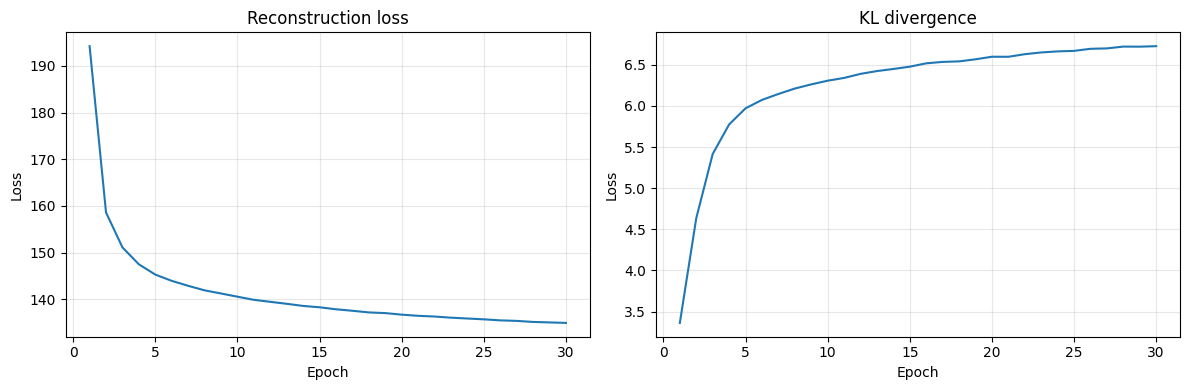

In [ ]:
import matplotlib.pyplot as plt

# Plot the two loss components side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name, title in zip(
    axes,
    ["reconstruction_loss", "kl_loss"],
    ["Reconstruction loss", "KL divergence"],
):
    values = history.history[name]
    ax.plot(range(1, len(values) + 1), values)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Explore the latent space

- We decode a regular grid of points from the two-dimensional latent space, with both coordinates ranging from −1 to 1. Each generated image is placed at its corresponding position in the grid.
- Nearby points typically produce similar digits, and moving through the latent space gradually changes their shape and appearance. Some regions may contain ambiguous digits or transitions between digit classes.

In [ ]:
import matplotlib.pyplot as plt


def plot_latent_grid(vae, x_range=(-1, 1), y_range=(-1, 1), n=30):
    """Decode and display a grid over the selected latent-space ranges."""
    digit_size = 28
    figure = np.zeros((digit_size * n, digit_size * n))

    grid_x = np.linspace(*x_range, n)
    grid_y = np.linspace(*y_range, n)[::-1]

    # Decode all grid points at once
    xx, yy = np.meshgrid(grid_x, grid_y)
    z_samples = np.stack([xx.ravel(), yy.ravel()], axis=1).astype("float32")
    decoded = vae.decoder.predict(z_samples, verbose=0)

    # Arrange the generated images into a grid
    for i in range(n):
        for j in range(n):
            figure[
                i * digit_size : (i + 1) * digit_size,
                j * digit_size : (j + 1) * digit_size,
            ] = decoded[i * n + j, :, :, 0]

    # Show a subset of coordinate labels for readability
    tick_indices = np.unique(np.linspace(0, n - 1, min(n, 10), dtype=int))
    pixel_positions = tick_indices * digit_size + digit_size // 2

    plt.figure(figsize=(12, 12))
    plt.imshow(figure, cmap="Greys_r")
    plt.xticks(pixel_positions, np.round(grid_x[tick_indices], 2), rotation=90)
    plt.yticks(pixel_positions, np.round(grid_y[tick_indices], 2))
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.tight_layout()
    plt.show()

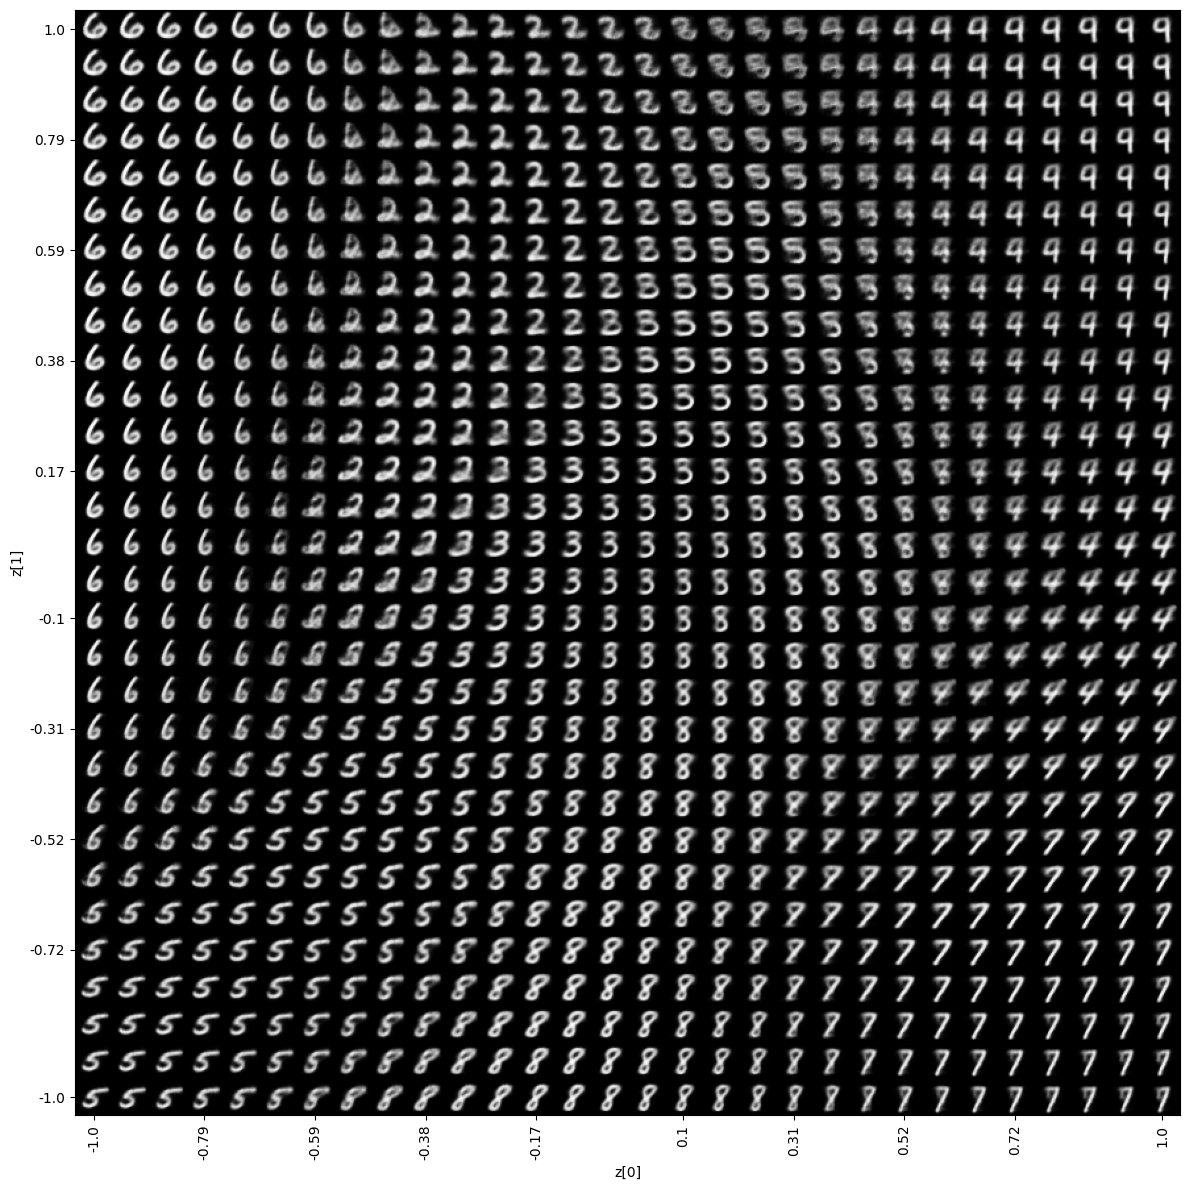

In [ ]:
# Explore a small region
plot_latent_grid(vae, x_range=(-1, 1), y_range=(-1, 1))

# Explore a larger region
# plot_latent_grid(vae, x_range=(-3, 3), y_range=(-3, 3))

#### Generate a digit from latent coordinates

Choose values for `z0` and `z1` and decode the corresponding latent vector into an image. Try changing the coordinates to explore how they affect the generated digit.

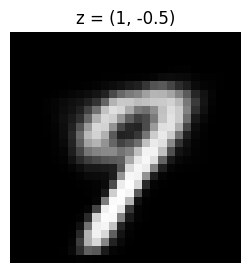

In [ ]:
# Choose a point in the latent space
z0 = 1
z1 = -0.5

# Decode the latent vector into an image
z_sample = np.array([[z0, z1]], dtype="float32")
generated_image = vae.decoder.predict(z_sample, verbose=0)

# Display the generated digit
plt.figure(figsize=(3, 3))
plt.imshow(generated_image[0, :, :, 0], cmap="Greys_r")
plt.title(f"z = ({z0}, {z1})")
plt.axis("off")
plt.show()

### Visualize digit classes in the latent space

We encode MNIST images and plot their latent mean vectors, using colors to distinguish digit classes. The labels are used only for visualization, not for training. Different classes may form clusters, although some overlap is expected.

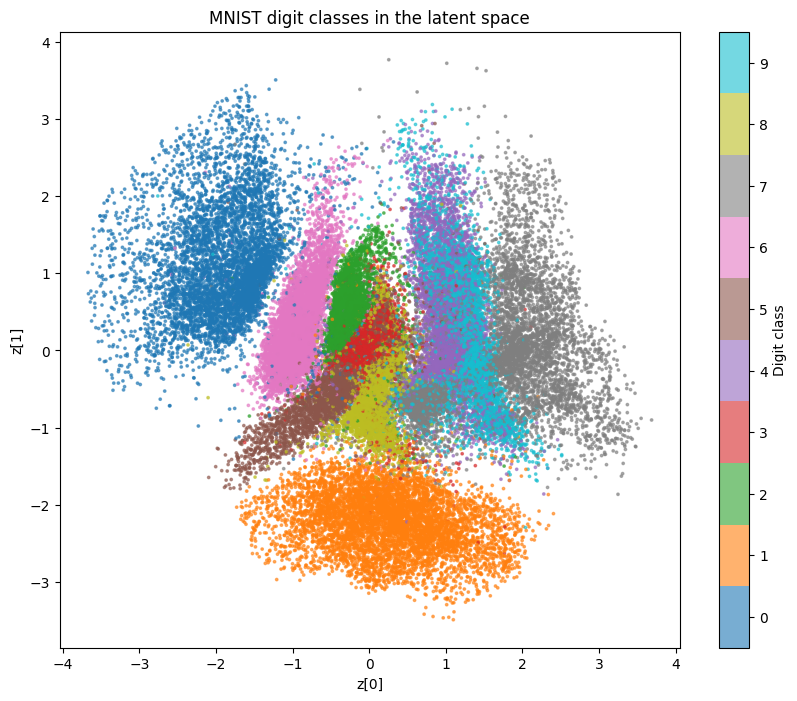

In [ ]:
def plot_label_clusters(vae, data, labels):
    """Plot latent mean vectors colored by digit class."""
    # Our encoder returns the mean and log variance
    z_mean, z_log_var = vae.encoder.predict(data, verbose=0)

    # Display the two-dimensional latent representations
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(
        z_mean[:, 0],
        z_mean[:, 1],
        c=labels,
        cmap="tab10",
        vmin=-0.5,
        vmax=9.5,
        s=3,
        alpha=0.6,
    )
    plt.colorbar(scatter, ticks=range(10), label="Digit class")
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.title("MNIST digit classes in the latent space")
    plt.show()


# Load images and labels for visualization
(x_train, y_train), _ = keras.datasets.mnist.load_data()
x_train = np.expand_dims(x_train, -1).astype("float32") / 255

plot_label_clusters(vae, x_train, y_train)

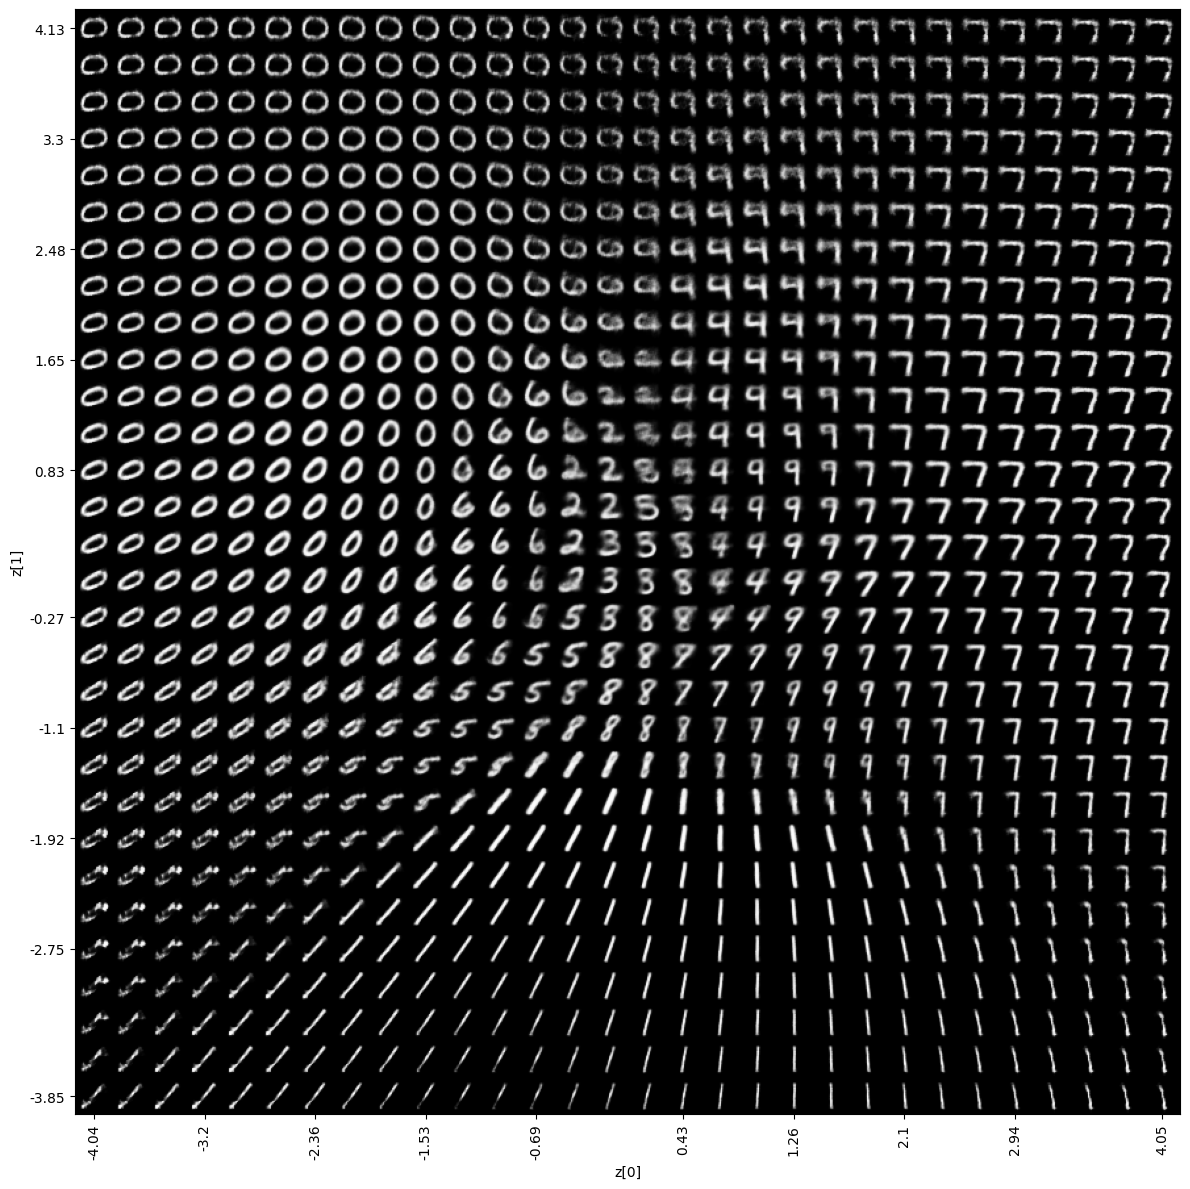

In [ ]:
# Explore the full range of encoded images, with a small margin
z_mean, _ = vae.encoder.predict(x_train, verbose=0)
z_min = z_mean.min(axis=0)
z_max = z_mean.max(axis=0)
margin = 0.05 * (z_max - z_min)

plot_latent_grid(
    vae,
    x_range=(z_min[0] - margin[0], z_max[0] + margin[0]),
    y_range=(z_min[1] - margin[1], z_max[1] + margin[1]),
)

### Generate variations of a selected digit

Choose a digit and generate variations by sampling from the latent distributions of several examples of that digit. Since this VAE is not class-conditioned, some generated images may resemble other digits.

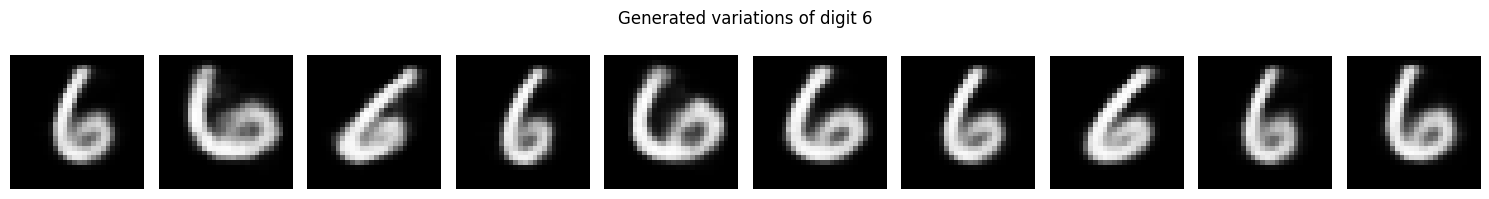

In [ ]:
# Choose the digit and the number of generated images
digit = 6
n_images = 10

# Select random examples of the chosen digit
rng = np.random.default_rng()
indices = rng.choice(
    np.flatnonzero(y_train == digit),
    size=n_images,
    replace=False,
)
examples = x_train[indices]

# Sample from their latent distributions and decode the samples
z_mean, z_log_var = vae.encoder.predict(examples, verbose=0)
z_samples = vae.sampler(z_mean, z_log_var)
generated_images = vae.decoder.predict(z_samples, verbose=0)

# Display the generated variations side by side
fig, axes = plt.subplots(
    1, n_images, figsize=(1.5 * n_images, 2), squeeze=False
)

for ax, image in zip(axes[0], generated_images):
    ax.imshow(image[:, :, 0], cmap="Greys_r")
    ax.axis("off")

fig.suptitle(f"Generated variations of digit {digit}")
plt.tight_layout()
plt.show()

### Interpolate between two digits

We encode two images and linearly interpolate between their latent mean vectors:

$$
z(t) = (1-t)z_A + tz_B, \qquad t \in [0, 1].
$$

Decoding these intermediate vectors shows how one reconstructed digit gradually changes into the other. Intermediate images may resemble other digit classes or ambiguous shapes.

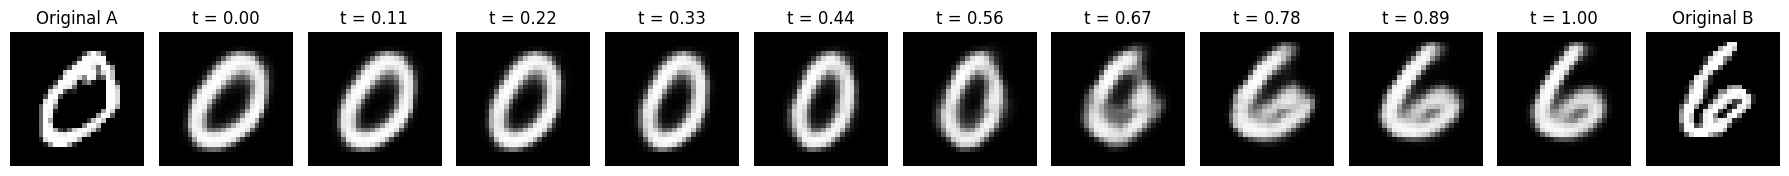

In [ ]:
# Choose two digit classes and select one image from each
digit_a = 0
digit_b = 6

image_a = x_train[y_train == digit_a][:1]
image_b = x_train[y_train == digit_b][:1]

# Encode both images using their latent means
z_mean, _ = vae.encoder.predict(np.concatenate([image_a, image_b]), verbose=0)

# Interpolate between the two latent vectors
n_steps = 10
t = np.linspace(0, 1, n_steps, dtype="float32")[:, None]
z_path = (1 - t) * z_mean[0] + t * z_mean[1]

# Decode all intermediate points at once
generated_images = vae.decoder.predict(z_path, verbose=0)

# Display the original images and the decoded transition
fig, axes = plt.subplots(1, n_steps + 2, figsize=(18, 3))

axes[0].imshow(image_a[0, :, :, 0], cmap="Greys_r")
axes[0].set_title("Original A")

for i, image in enumerate(generated_images):
    axes[i + 1].imshow(image[:, :, 0], cmap="Greys_r")
    axes[i + 1].set_title(f"t = {t[i, 0]:.2f}")

axes[-1].imshow(image_b[0, :, :, 0], cmap="Greys_r")
axes[-1].set_title("Original B")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Try it yourself

- Explore different regions of the latent space.
- Interpolate between different pairs of digits.
- Compare the generated images with the class clusters. Are digit classes clearly separated?